# Evaluation and ablation
We compare proposal-level novelty, feasibility, clarity, importance and evidence grounding (1–5).
A separately prompted judge sees the idea and separately searched local corpus evidence, without system label,
review scores or refinement history. Same-model judging still risks preference and knowledge bias.
A shuffled, blinded human-rating CSV is generated for later calibration; blank ratings are not evidence.


**Corrected live pilot (`smoke_v2`):** All twelve final-condition rows have accepted independent ratings, and all sixteen distinct judged proposals passed validation. One generic-review run stopped early on a wrong-role response. The full panel has higher mean feasibility, clarity and grounding but lower mean novelty than one-shot in this two-seed sample. These are preliminary proposal-level ratings; no statistical superiority or human validation is claimed. The earlier quotation-failure pilot remains preserved in `results/smoke`.


In [1]:
from pathlib import Path
import sys, os, json
ROOT = Path.cwd() if (Path.cwd() / 'src' / 'research_review').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / 'src'))
from research_review.config import Settings, budget
from research_review.schemas import Paper, Run
from research_review.storage import load_json
from research_review.literature_retrieval import create_retriever
from research_review.llm import GeminiClient
from research_review.experiments import run_study
settings = Settings.from_env()
study = ROOT / 'results' / os.getenv('RESEARCH_REVIEW_STUDY', 'smoke_v2')
seeds = [Paper.model_validate(p) for p in load_json(ROOT / 'data' / 'smoke_seeds.json')]
retriever = create_retriever(settings)
RUN_LIVE = os.getenv('RUN_LIVE_EXPERIMENTS') == '1'
print('Model:', settings.model, '| rounds:', settings.rounds)
print('Credentials configured:', bool(os.getenv('GEMINI_API_KEY') or os.getenv('GOOGLE_API_KEY')))
print('Live execution opt-in:', RUN_LIVE)
print('Fixed smoke seeds:', [(p.paper_id, p.year, p.title) for p in seeds])


Model: gemini-3.5-flash-lite | rounds: 3
Credentials configured: True
Live execution opt-in: False
Fixed smoke seeds: [('2025.naacl-long.342', 2025, 'ResearchAgent: Iterative Research Idea Generation over Scientific Literature with Large Language Models'), ('2024.acl-long.18', 2024, 'SciMON: Scientific Inspiration Machines Optimized for Novelty')]


## Ablations
Removing feasibility tests the contribution of practical constraint critique. Removing contrarian review
tests adversarial challenge. Removing novelty retrieval retains the novelty persona and seed context
but removes its wider prior-art search. These are removal studies at unequal natural call budgets;
any changes may reflect both content and inference allocation.


In [2]:
if RUN_LIVE:
    client = GeminiClient(settings, study / 'api_audit')
    run_study(seeds, client, retriever, settings, study,
              configurations=['no_feasibility', 'no_contrarian', 'no_novelty_retrieval'])
else:
    print('Live ablations disabled; no synthetic scores substituted.')


Live ablations disabled; no synthetic scores substituted.


In [3]:
runs = [Run.model_validate(load_json(p)) for p in (study / 'runs').glob('*.json') if not p.name.endswith('.partial.json')]
print('Saved live runs:', sum(r.provenance == 'live_gemini' for r in runs))
if not runs:
    print('NOT RUN: No live generated proposals are available. Dataset and software checks are not experimental findings.')


Saved live runs: 12


In [4]:
from research_review.evaluation import evaluate_runs
if RUN_LIVE and runs:
    judge = GeminiClient(settings, study / 'judge_api_audit')
    evaluate_runs(runs, judge, retriever, settings, study / 'evaluation')
else:
    print('Independent evaluation not executed in this cell.')


Independent evaluation not executed in this cell.


## Analysis and figures
Analyze final proposals across baselines and ablations, then the full panel's initial and rounds 1–3.
Reuse one judgment for identical content. The seed is the independent unit; repeated runs collapse
within seed. Report all five dimension scores, paired changes, ties and missing judgments.
Descriptive statistics remain primary for small samples. Exploratory Wilcoxon tests require at least ten
nonzero paired seed differences; Holm adjustment covers tested comparisons. Ordinal score distances,
symmetry assumptions and purposive sampling limit interpretation. API time/calls/tokens are separate
from judging costs; shared initial generation is recorded once in `initials/`.


In [5]:
from research_review.analysis import analyze
status = analyze(study)
print(json.dumps(status, indent=2))
if status['status'] == 'analyzed':
    import pandas as pd
    print(pd.read_csv(study / 'analysis' / 'summary.csv', header=[0,1]).to_string())
    print(pd.read_csv(study / 'analysis' / 'paired_comparisons.csv').to_string(index=False))
    try:
        from IPython.display import display, Image
    except ImportError:
        print('Rich display requires IPython; actual PNG/PDF figures are saved in', study / 'analysis')
    else:
        for filename in ['baseline_comparison', 'ablation_comparison', 'iteration_progression',
                         'novelty_feasibility', 'execution_time']:
            display(Image(filename=str(study / 'analysis' / (filename + '.png'))))
else:
    print('No empirical comparison, statistical claim or quality figure can yet be reported.')


{
  "status": "analyzed",
  "valid_score_rows": 26,
  "failed_score_rows": 0,
  "n_seeds": 2,
  "n_final_rows": 12,
  "limitations": "Same-model judge bias, abstract-only search coverage, natural unequal budgets, purposive seeds, no human calibration yet. Missing judgments excluded and counted; no claim of scientific success."
}
     Unnamed: 0_level_0 novelty                       feasibility                       clarity                       importance                       evidence_grounding                      
     Unnamed: 0_level_1   count mean median       std       count mean median       std   count mean median       std      count mean median       std              count mean median       std
0         configuration     NaN  NaN    NaN       NaN         NaN  NaN    NaN       NaN     NaN  NaN    NaN       NaN        NaN  NaN    NaN       NaN                NaN  NaN    NaN       NaN
1              one_shot     2.0  4.0    4.0  0.000000         2.0  3.5    3.5  0.707107     2

## Findings and limitations
Answer from observed scores: Did novelty or feasibility improve? Was there a trade-off? Which removal
changed scores most? Did quality plateau or reverse across rounds? Did cited prior work reveal overlap?
If results are absent, these questions remain unanswered.

Limits: narrow purposive seed sample; abstract-only local retrieval; bounded corpus coverage and lexical ranking effects;
same-model judge and generator; no completed human calibration; unequal call budgets; possible model
memorization; proposal-level feasibility is not executed research. Do not generalize a two-seed smoke study
or claim training, statistical superiority, or successful scientific discovery.


## Actual saved figures: smoke_v2
These figures use saved independent ratings. Sample counts and missing judgments limit comparisons.

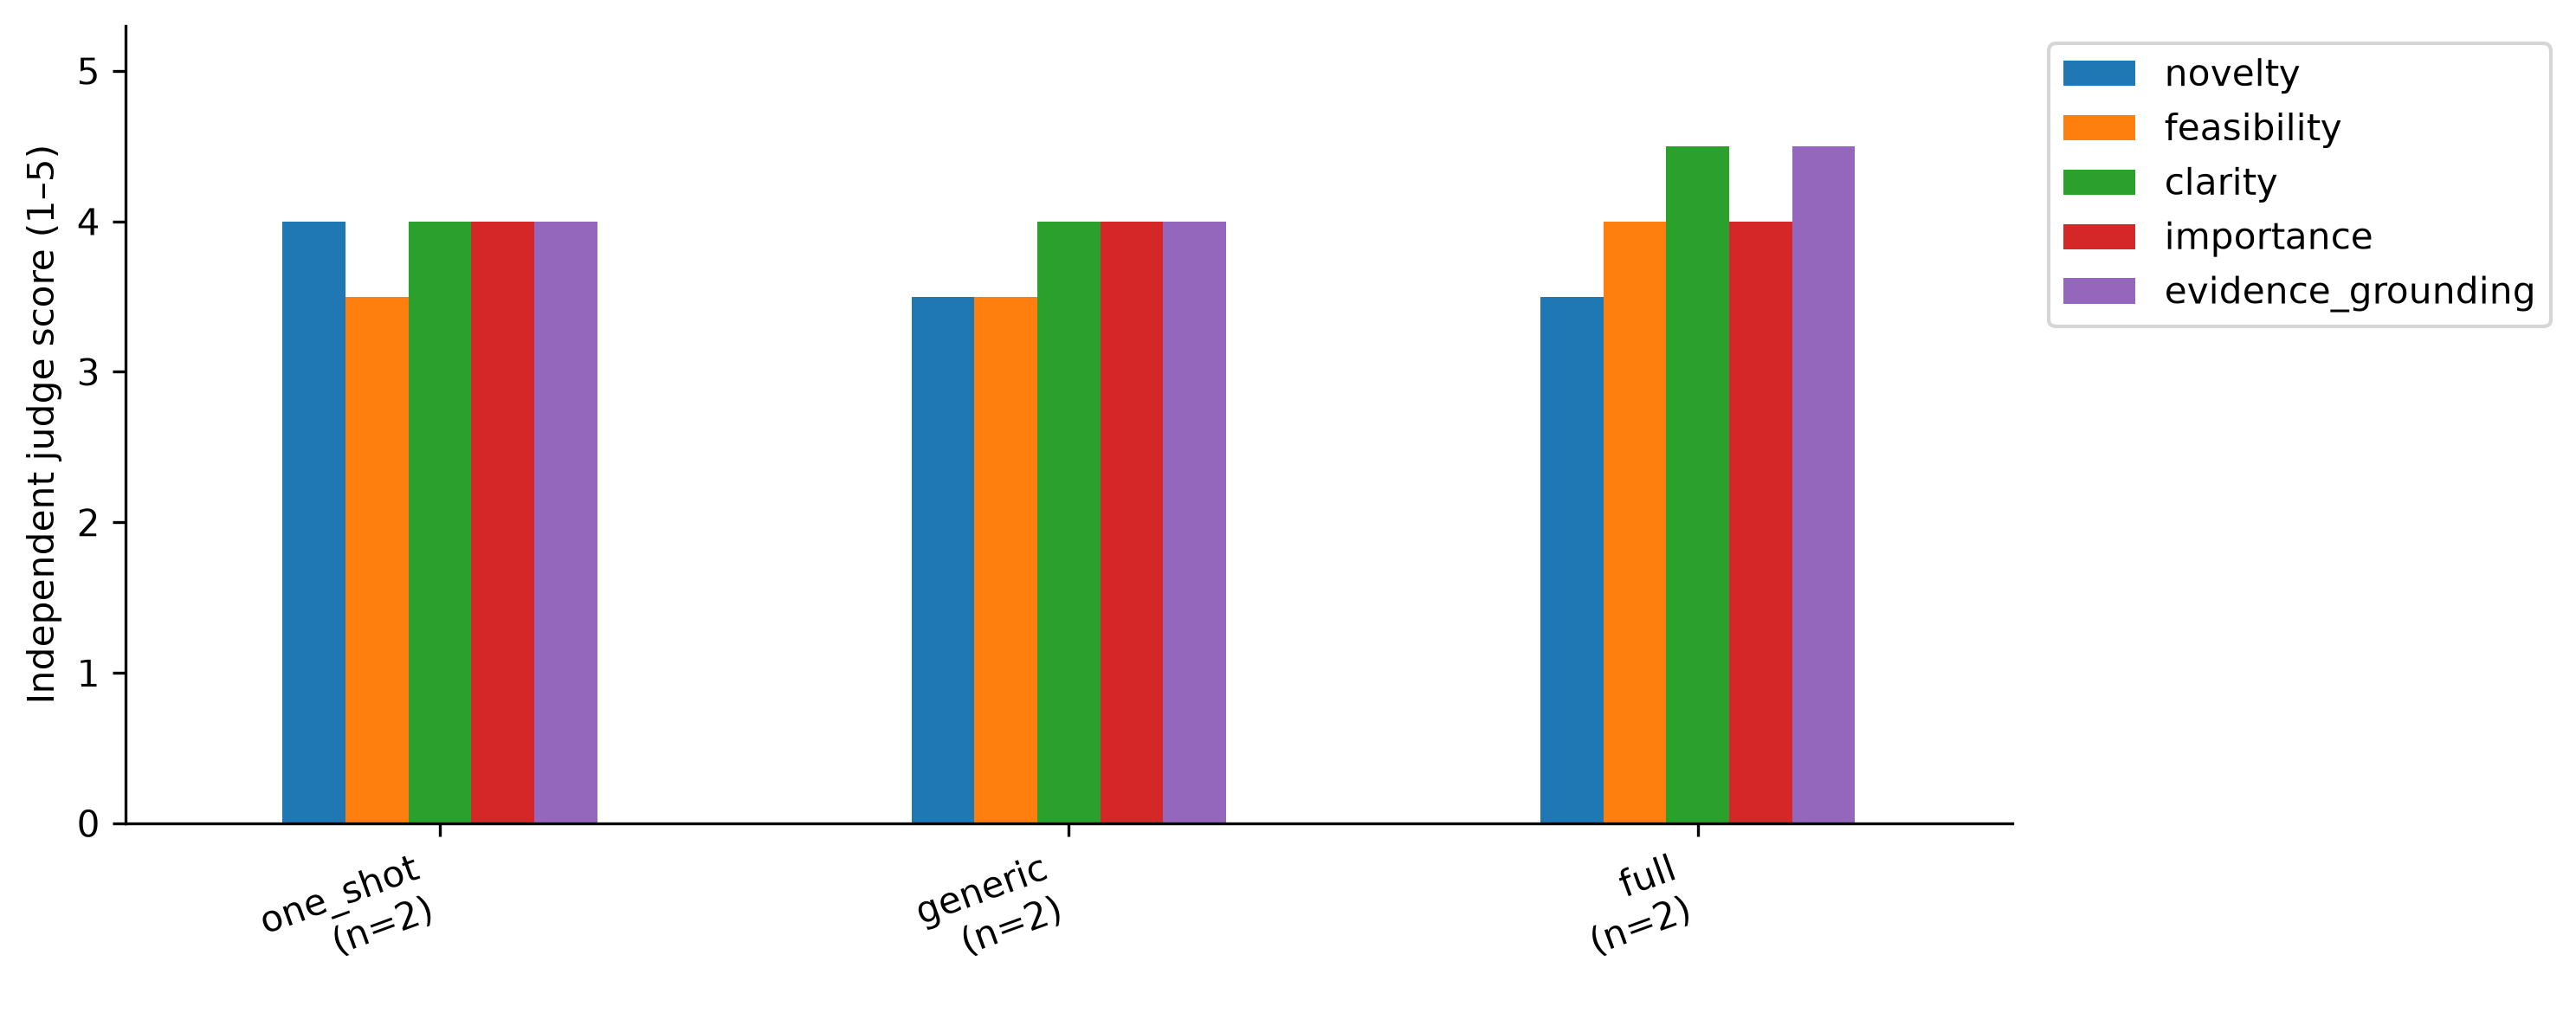

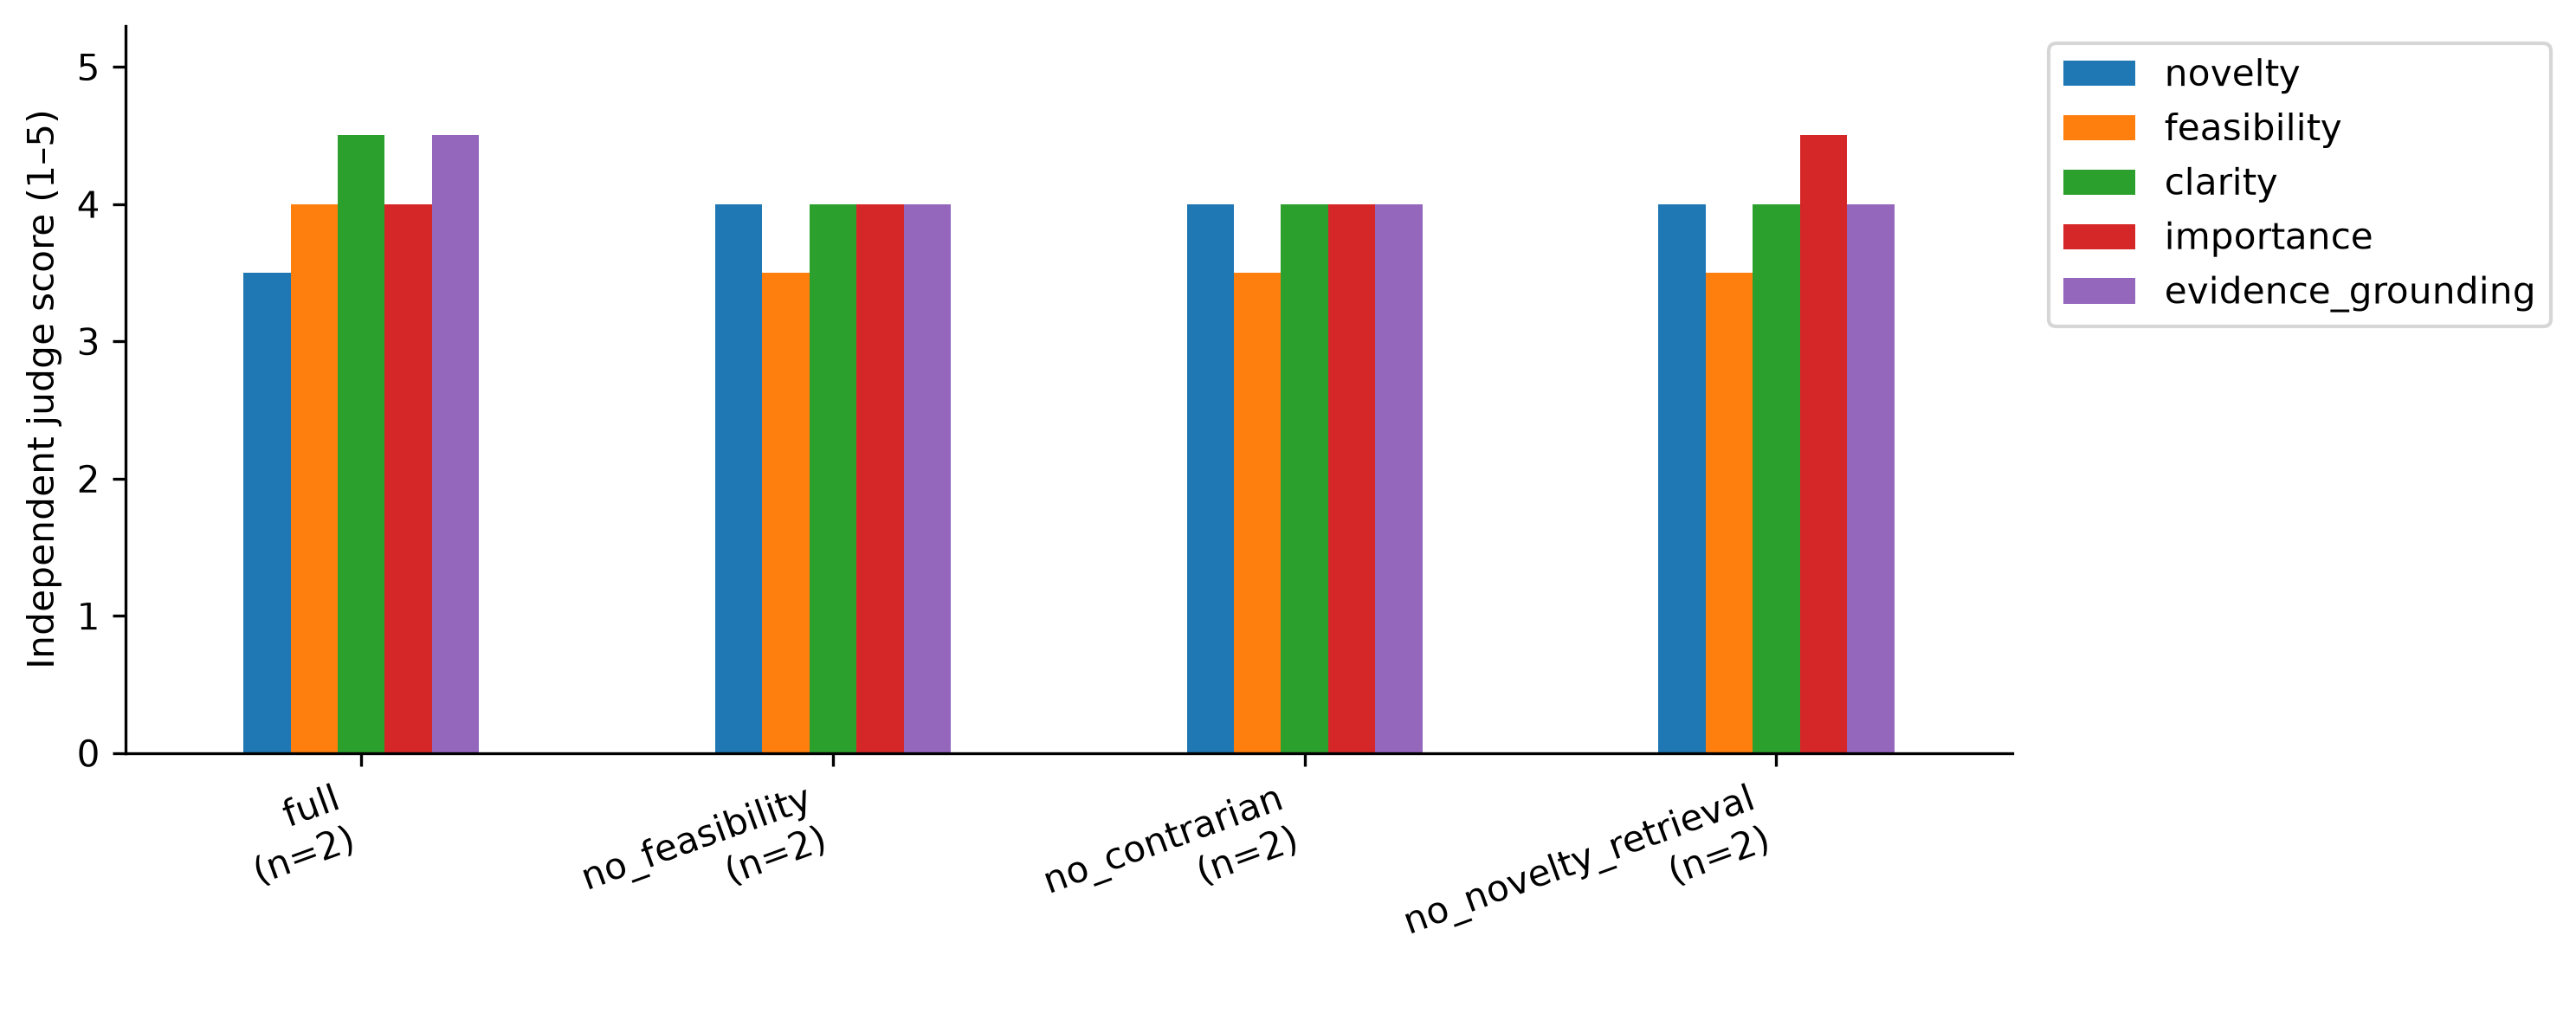

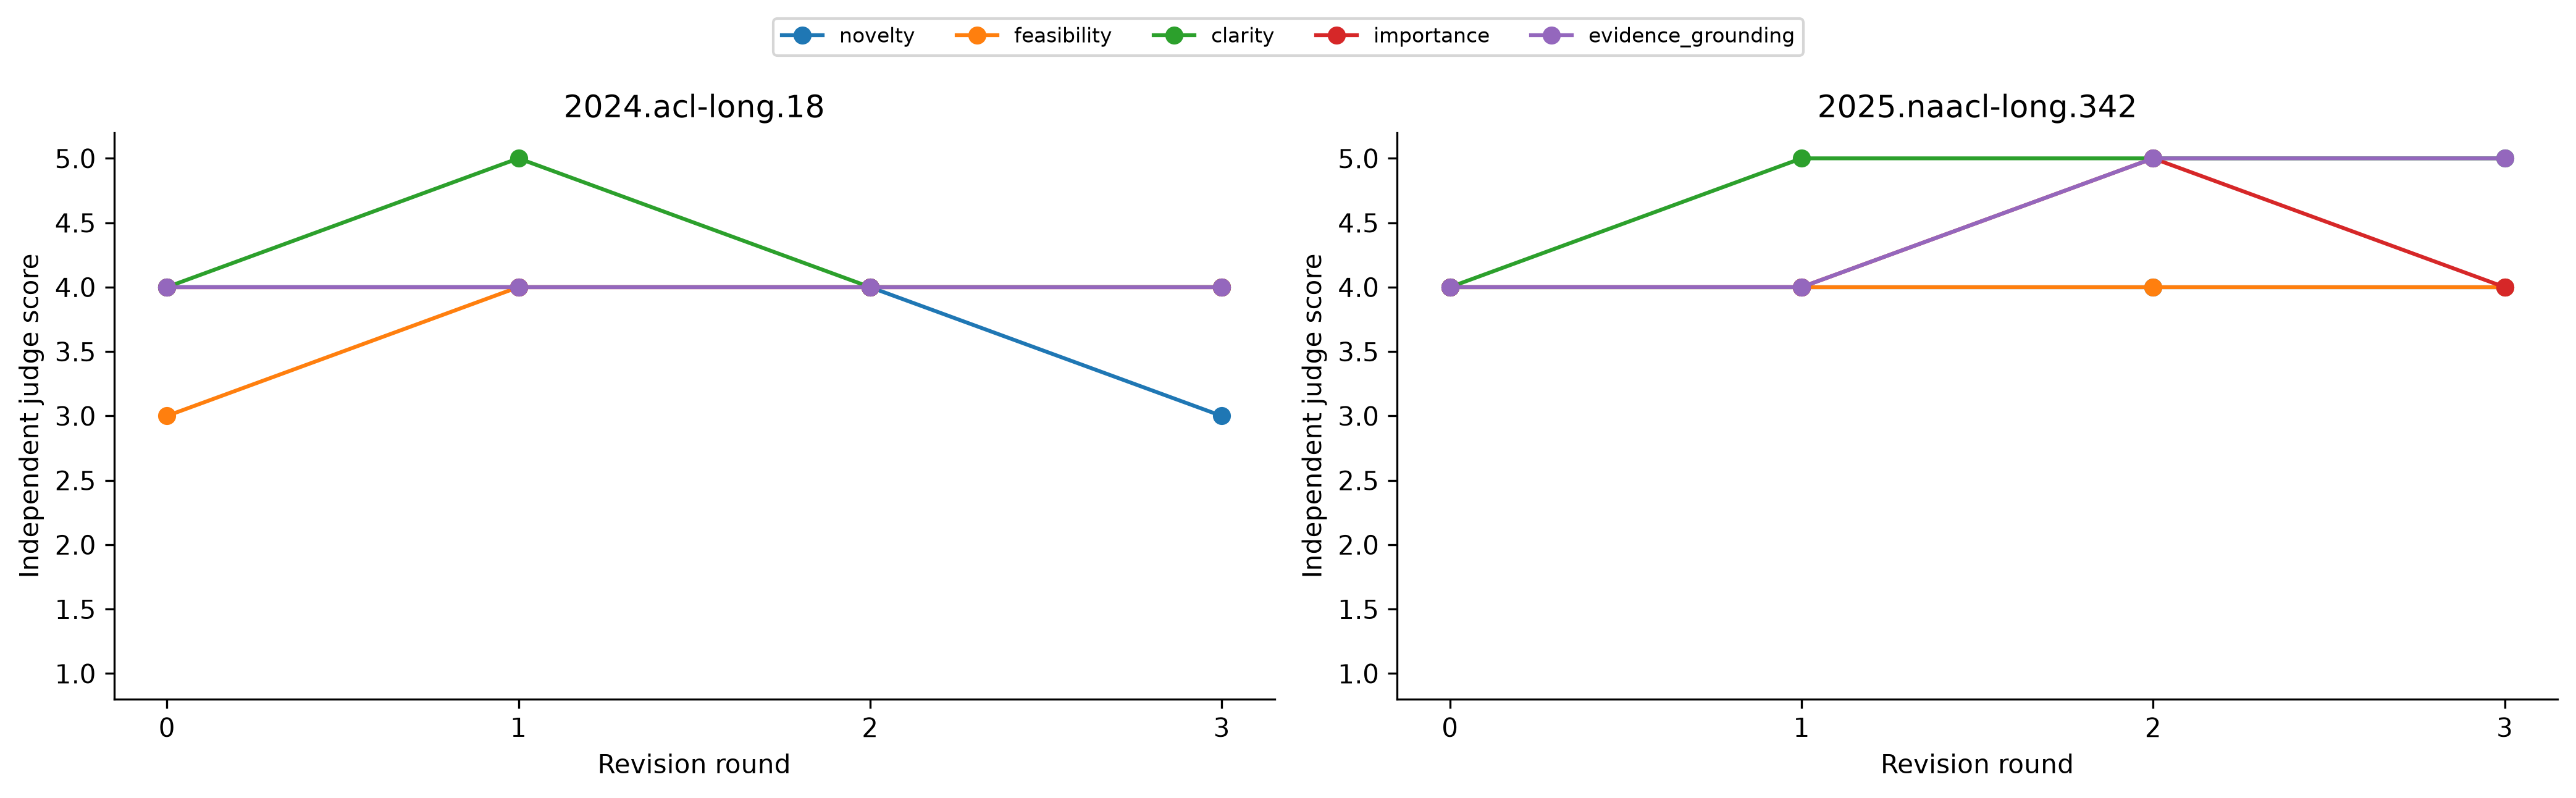

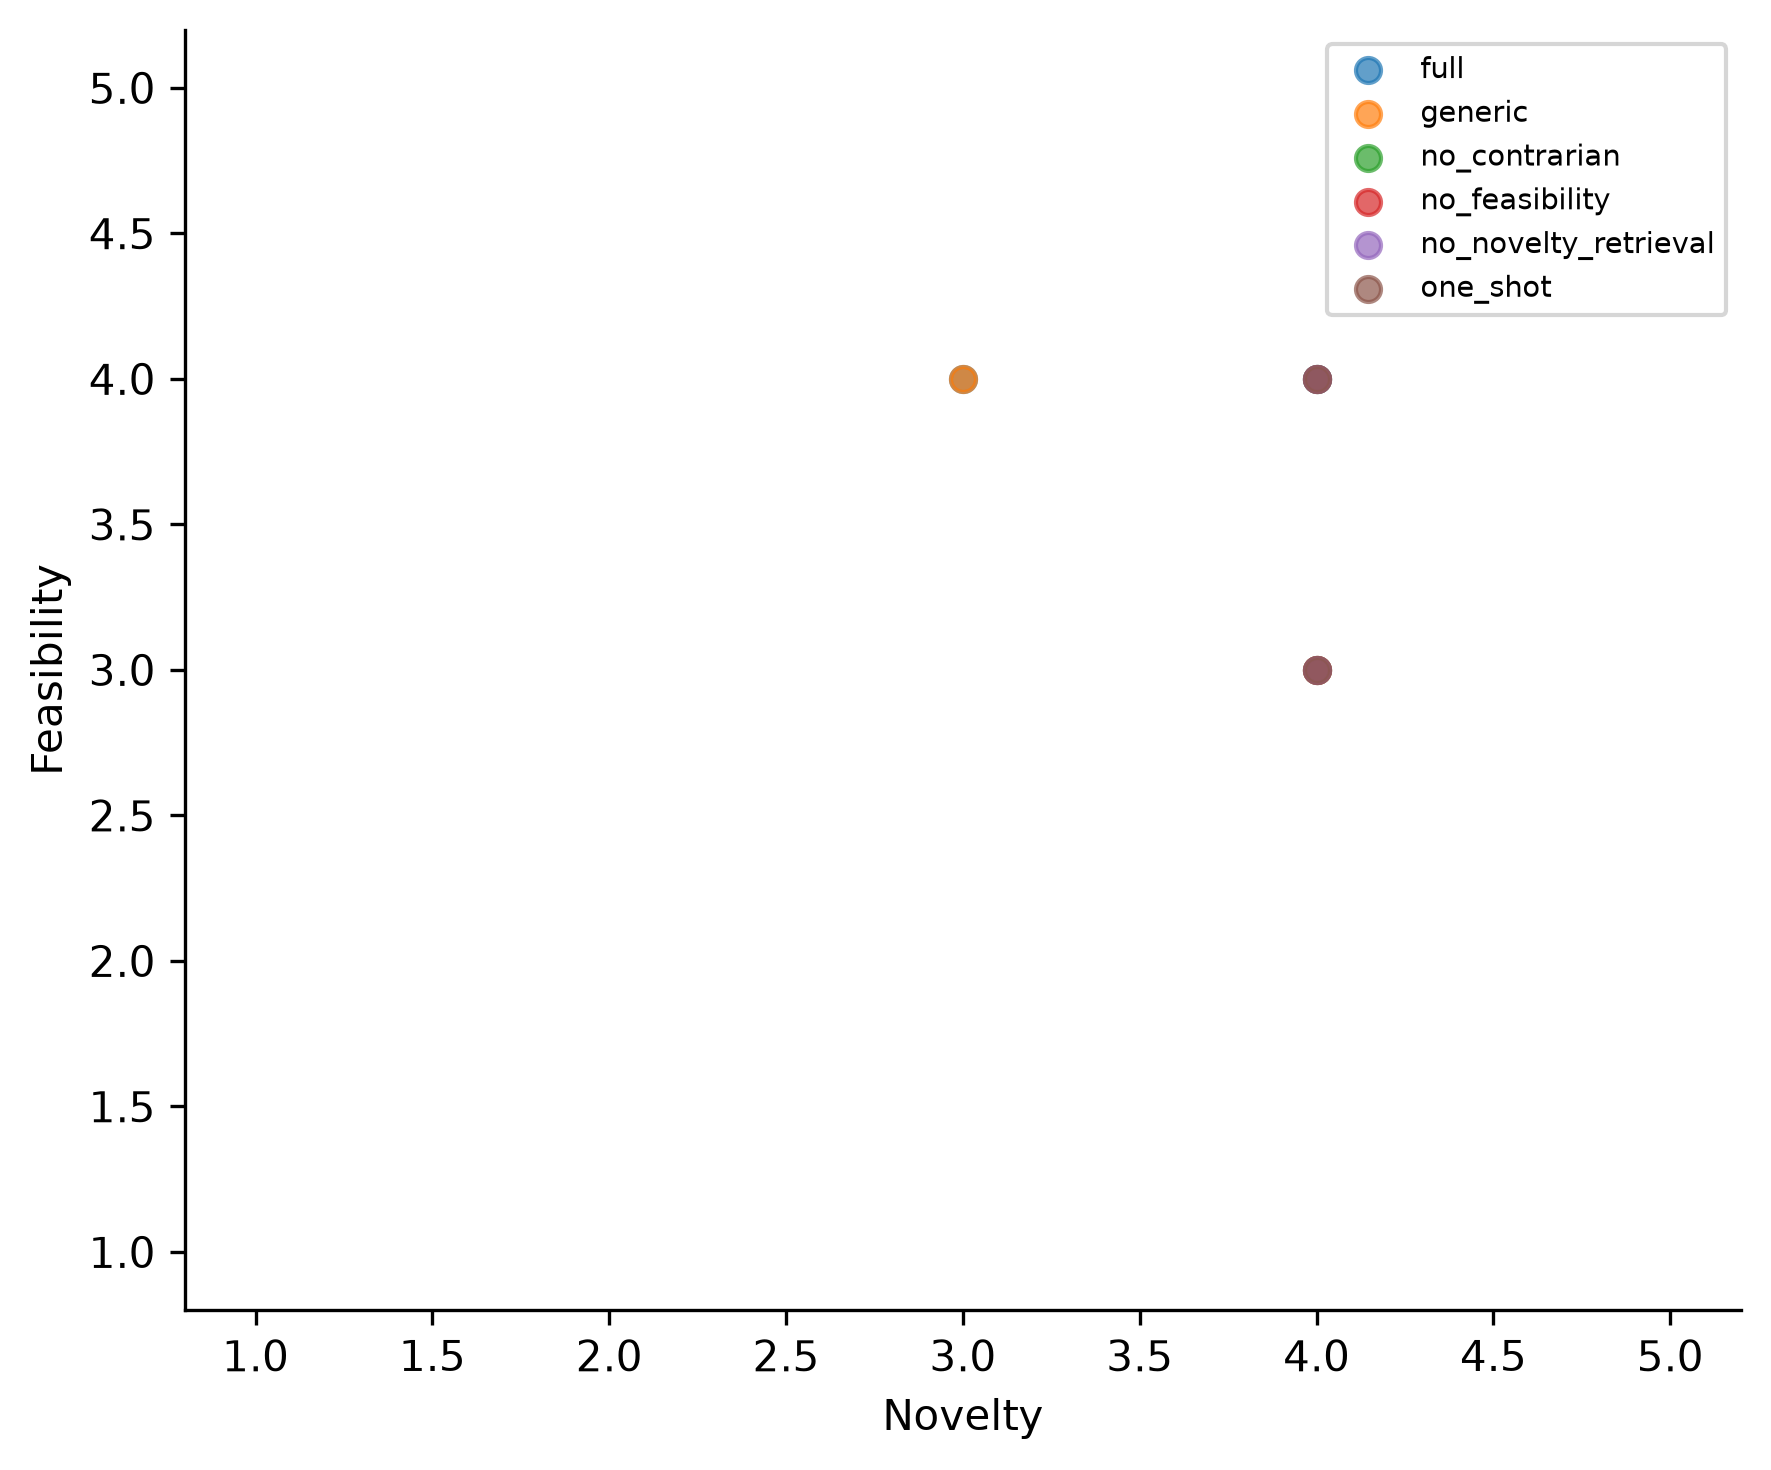

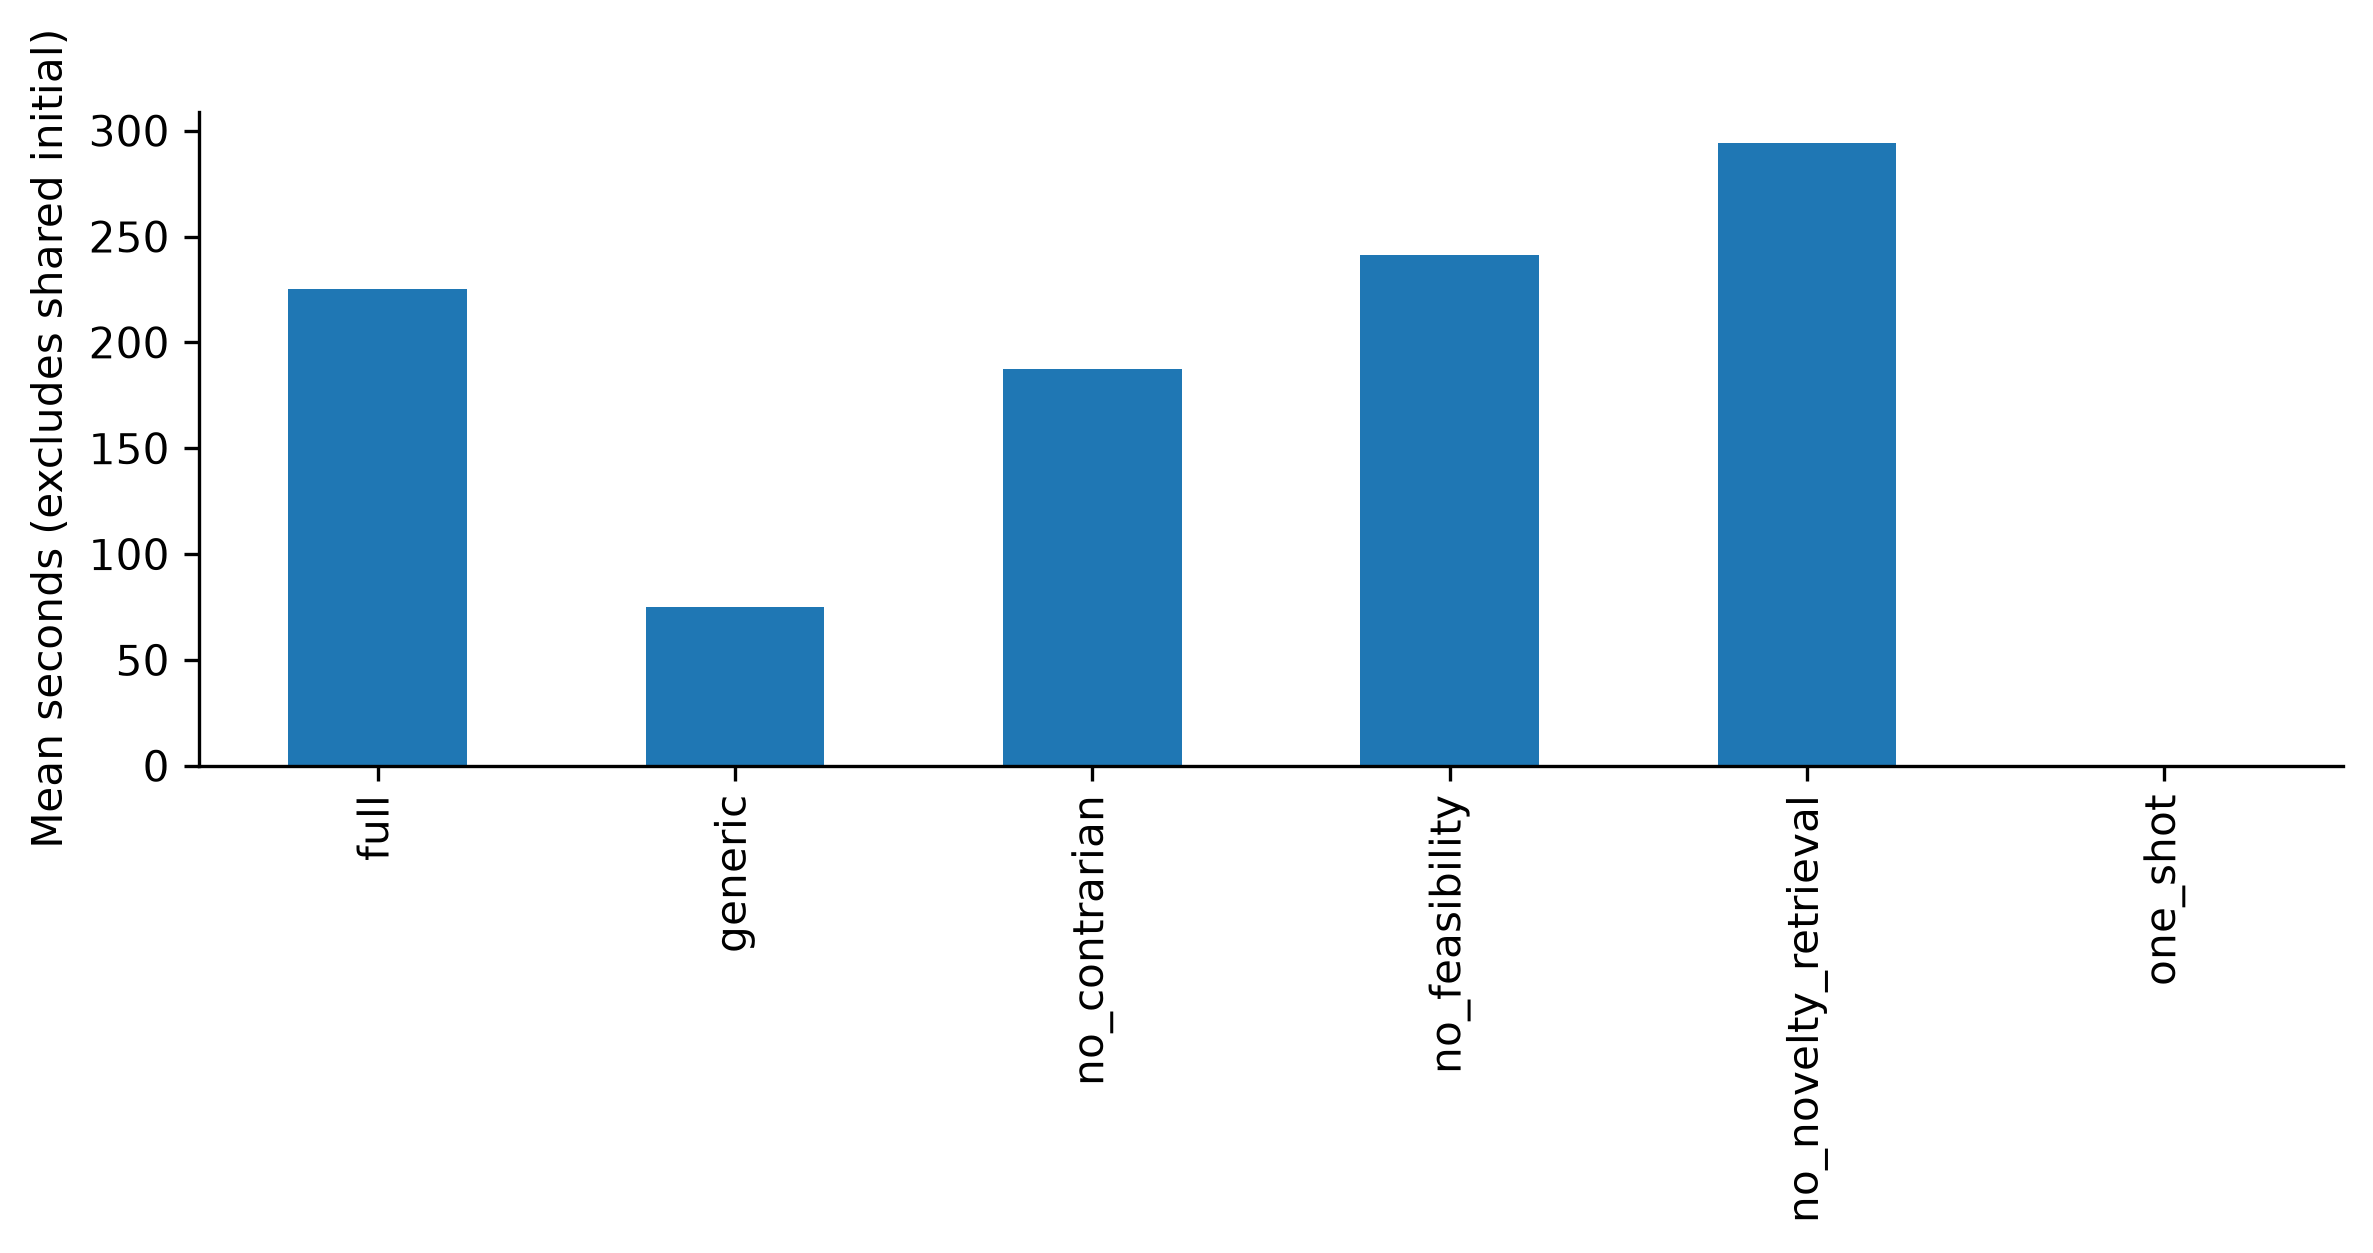
